# 5. 템플릿 매칭 (Template Matching)

**셀을 위에서부터 차례로 실행**하며 배운다. 설명과 코드는 MD와 IPYNB에서 같은 순서다. IPYNB에는 실행 결과가 저장되어 있다.

## 시작하기

- ZIP을 풀고 폴더 안의 노트북을 Jupyter 또는 VS Code에서 연다.
- 노트북 작업 폴더를 `Template_Matching_Notes`로 설정한다. 경로가 다르면 셀 1의 `ROOT`만 바꾼다.
- 패키지가 없다면 별도 셀에서 `%pip install opencv-python numpy matplotlib`를 실행하고 커널을 재시작한다.
- 이후 **Restart Kernel → Run All**로 처음부터 실행한다.
- 그림은 셀 아래에 표시되고 `assets`에도 저장된다. 옵시디언에서는 MD와 assets를 같은 폴더에 둔다.

## 5.1 템플릿 매칭의 원리

- 큰 사진에서 작은 사진 조각과 비슷한 곳을 찾는다.
- 조각을 한 칸씩 옮기며 겹치는 부분과 비교한다.
- 각 위치의 비교 점수를 모은 배열이 **응답 맵(response map)**이다.
- 응답 맵의 좌표는 템플릿을 놓는 **왼쪽 위 위치**다.

$$
\text{입력 }(H,W),\quad \text{템플릿 }(h,w)
\quad\Rightarrow\quad \text{응답 맵 }(H-h+1,W-w+1)
$$

입력·템플릿은 같은 자료형과 채널 구성을 사용하고, 템플릿은 입력보다 크지 않아야 한다. 이번에는 둘 다 8비트 Gray로 맞춘다.

### 셀 1. 모듈과 경로 준비

In [1]:
# 셀 1: 입력 경로와 공통 함수
# 원본과 템플릿을 읽고 결과 그림을 저장·표시할 준비를 한다.

# Path는 운영체제에 맞게 파일 경로를 조합하는 데 사용한다.
from pathlib import Path
import csv
import json
# OpenCV는 영상 처리, NumPy는 배열 계산, Matplotlib은 결과 시각화에 사용한다.
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# 현재 작업 폴더를 기준으로 assets를 찾는다. 노트북은 각 장의 폴더에서 실행한다.
ROOT = Path.cwd()  # 노트북 파일이 있는 폴더에서 실행
ASSETS = ROOT / 'assets'
assert (ASSETS / 'Lenna.png').is_file(), 'ROOT를 실습 폴더 경로로 바꾸세요.'

def read_image(name):
    # 파일을 바이트 배열로 읽어 디코딩한다. IMREAD_COLOR의 결과는 BGR 순서다.
    img = cv2.imdecode(np.fromfile(ASSETS / name, np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(name)
    return img

# 비교 그림의 배치를 통일하고, 영상 또는 결과 배열을 화면에 표시한다.
def save_show(fig, name):
    fig.tight_layout()
    fig.savefig(ASSETS / name, dpi=140)
    plt.show()
    plt.close(fig)

print('OpenCV:', cv2.__version__)

OpenCV: 5.0.0


### 셀 2. 제공된 레나와 템플릿 읽기

원본과 템플릿을 실제로 확인한다. 제공된 템플릿의 정답 위치는 미리 지정하지 않고 탐색한다.

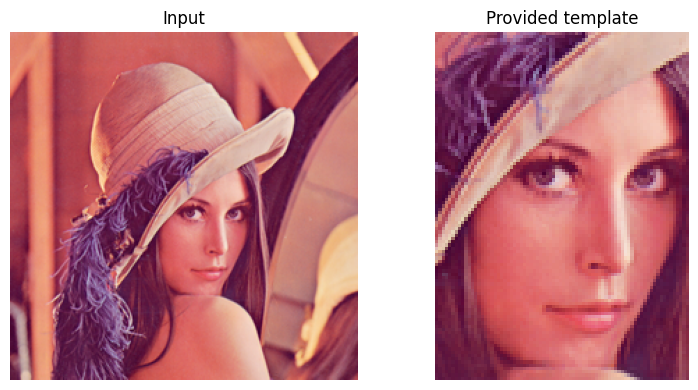

입력: (250, 250) 템플릿: (107, 78)
예상 응답 맵: (144, 173)


In [2]:
# 셀 2: 입력 영상과 템플릿 검사
# 크기·자료형을 맞추고, 분산이 없는 단색 템플릿을 제외한다.

bgr = read_image('Lenna.png')
template_bgr = read_image('template.png')
# B·G·R을 밝기 가중합으로 바꾸어 단일 채널 영상으로 만든다.
image = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
# B·G·R을 밝기 가중합으로 바꾸어 단일 채널 영상으로 만든다.
template = cv2.cvtColor(template_bgr, cv2.COLOR_BGR2GRAY)
# shape는 (높이, 너비) 순서다. 좌표 (x, y)로 읽을 때는 배열 인덱스 [y, x]와 구분한다.
H, W = image.shape
# shape는 (높이, 너비) 순서다. 좌표 (x, y)로 읽을 때는 배열 인덱스 [y, x]와 구분한다.
h, w = template.shape
assert h <= H and w <= W
assert image.dtype == template.dtype == np.uint8
assert template.std() > 1e-6, '단색 템플릿은 피하세요.'
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); ax[0].set_title('Input')
ax[1].imshow(cv2.cvtColor(template_bgr, cv2.COLOR_BGR2RGB)); ax[1].set_title('Provided template')
for a in ax: a.axis('off')
save_show(fig, 'inputs.png')
print('입력:', image.shape, '템플릿:', template.shape)
print('예상 응답 맵:', (H-h+1, W-w+1))

## 5.2 여섯 가지 매칭 방법

템플릿 픽셀을 $T_i$, 현재 입력 영역의 픽셀을 $P_i$라 하자. 합은 템플릿의 모든 픽셀에 대해 계산한다.

$$
E=\sqrt{\left(\sum_iT_i^2\right)\left(\sum_iP_i^2\right)},\qquad
T'_i=T_i-\overline T,\quad P'_i=P_i-\overline P
$$

### A. 제곱 차: TM_SQDIFF

$$R=\sum_i(T_i-P_i)^2$$

- 서로 다른 만큼 벌점을 더한다. **작을수록 좋다.**
- 정확히 같으면 이론적으로 0이지만 실제 계산에는 작은 오차가 있을 수 있다.

### B. 정규화 제곱 차: TM_SQDIFF_NORMED

$$R=\frac{\sum_i(T_i-P_i)^2}{E}$$

- 제곱 차를 에너지로 나눈다. **작을수록 좋다.**
- 정규화했다고 모든 밝기 변화에 강해지는 것은 아니다.
- 분모가 작거나 0인 영역은 주의한다. 이 수식만으로 모든 입력에 0~1 범위를 보장한다고 해석하지 않는다.

### C. 교차 상관: TM_CCORR

$$R=\sum_iT_iP_i$$

- 같은 위치의 값을 곱해 더한다. **클수록 좋다.**
- 밝은 영역에 큰 점수를 줄 수 있어 정확한 모양이 아닌 곳이 선택될 수 있다.

### D. 정규화 교차 상관: TM_CCORR_NORMED

$$R=\frac{\sum_iT_iP_i}{E}$$

- 값의 크기를 보정해 패턴을 비교한다. **클수록 좋다.**
- 이번처럼 음수가 없는 입력에서 분모가 양수이면 이론적 범위는 0~1이다.

### E. 평균 제거 상관: TM_CCOEFF

$$R=\sum_iT'_iP'_i$$

- 각 영역의 평균을 빼고 변화 모양을 비교한다. **클수록 좋다.**
- 정규화하지 않은 값이므로 −1~1로 제한되지 않는다.

### F. 정규화 상관 계수: TM_CCOEFF_NORMED

$$R=\frac{\sum_iT'_iP'_i}{\sqrt{\left(\sum_iT_i'^2\right)\left(\sum_iP_i'^2\right)}}$$

- **클수록 좋다.** 분모가 양수이면 이론적으로 −1~1이다.
- 1은 양의 선형 관계, −1은 반대 방향의 선형 관계, 0은 선형 상관이 없음을 뜻한다.
- −1이 모든 종류의 ‘완전 불일치’, 0이 모든 의미의 ‘무관함’을 뜻하지는 않는다.
- 점수 0.9를 검출 확률 90%로 해석하면 안 된다.

> **주의:** 단색 템플릿이나 분산이 0인 영역에서는 정규화 계수의 분모가 0이 될 수 있다. 반환값에만 의존하지 말고 유효한 텍스처와 분산을 확인한다.

밝기가 $P=aT+b$로 바뀌고 $a>0$, 분산이 양수이며 클리핑이 없다면 CCOEFF_NORMED는 이론적으로 1이다. 그러나 그림자, 가림, 비선형 조명 변화까지 해결하지는 않는다.

### 셀 3. 여섯 가지 방법 실행

응답 맵마다 점수 단위가 다르므로 **다른 방법의 숫자를 그대로 비교해 우열을 정하지 않는다.**

In [3]:
# 셀 3: 여섯 가지 매칭 방법 비교
# SQDIFF 계열은 최솟값, 나머지는 최댓값의 위치를 최적 후보로 선택한다.

methods = ['TM_SQDIFF', 'TM_SQDIFF_NORMED', 'TM_CCORR',
           'TM_CCORR_NORMED', 'TM_CCOEFF', 'TM_CCOEFF_NORMED']
responses = {}
rows = []
for name in methods:
    # 템플릿을 움직이며 위치별 점수를 계산한다. 출력의 각 축 크기는 입력 크기에서 템플릿 크기를 뺀 뒤 1을 더한 값이다.
    response = cv2.matchTemplate(image, template, getattr(cv2, name))
    assert response.shape == (H-h+1, W-w+1)
    assert np.isfinite(response).all()
    # minMaxLoc은 점수의 최솟값·최댓값과 각각의 (x, y) 좌표를 반환한다.
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(response)
    # 제곱 차는 오차이므로 작을수록 좋고, 상관 계열은 클수록 좋은 후보로 선택한다.
    use_min = name in ('TM_SQDIFF', 'TM_SQDIFF_NORMED')
    score, loc = (min_val, min_loc) if use_min else (max_val, max_loc)
    responses[name] = response
    rows.append({'method': name, 'best': 'min' if use_min else 'max',
                 'score': score, 'x': loc[0], 'y': loc[1]})
header = '| 방법 | 최적 기준 | 점수 | x | y |\n| :---: | :---: | :---: | :---: | :---: |'
lines = [f"| {r['method']} | {r['best']} | {r['score']:.6g} | {r['x']} | {r['y']} |" for r in rows]
display(Markdown(header + '\n' + '\n'.join(lines)))
with (ROOT / 'matching_results.csv').open('w', newline='', encoding='utf-8-sig') as fp:
    # 사전의 키를 CSV 열 이름으로 사용하며, 각 매칭 방법의 점수와 좌표를 행으로 저장한다.
    writer = csv.DictWriter(fp, fieldnames=rows[0].keys())
    writer.writeheader(); writer.writerows(rows)

| 방법 | 최적 기준 | 점수 | x | y |
| :---: | :---: | :---: | :---: | :---: |
| TM_SQDIFF | min | 32 | 96 | 86 |
| TM_SQDIFF_NORMED | min | 3.01826e-07 | 96 | 86 |
| TM_CCORR | max | 1.59271e+08 | 104 | 18 |
| TM_CCORR_NORMED | max | 1 | 96 | 86 |
| TM_CCOEFF | max | 2.22259e+07 | 96 | 86 |
| TM_CCOEFF_NORMED | max | 0.999999 | 96 | 86 |

## 5.3 최적 위치 탐색과 결과 표시

- `minMaxLoc()`은 최솟값·최댓값과 각각의 위치를 반환한다.
- SQDIFF 두 종류는 최솟값, 나머지 네 종류는 최댓값을 선택한다.
- 반환 좌표는 `(x, y)`지만 배열 접근은 `[y, x]`다.
- 검출 영역은 `image[y:y+h, x:x+w]`다.
- 정수 픽셀 범위를 정확히 그리려면 사각형의 끝점을 `(x+w-1, y+h-1)`로 둔다.

### 셀 4. 응답 맵과 사각형 비교

각 응답 맵에는 독립적인 색 범위를 사용한다. SQDIFF는 어두운 점, 나머지는 밝은 점이 최적일 수 있으므로 표시된 점과 기준을 함께 확인한다.

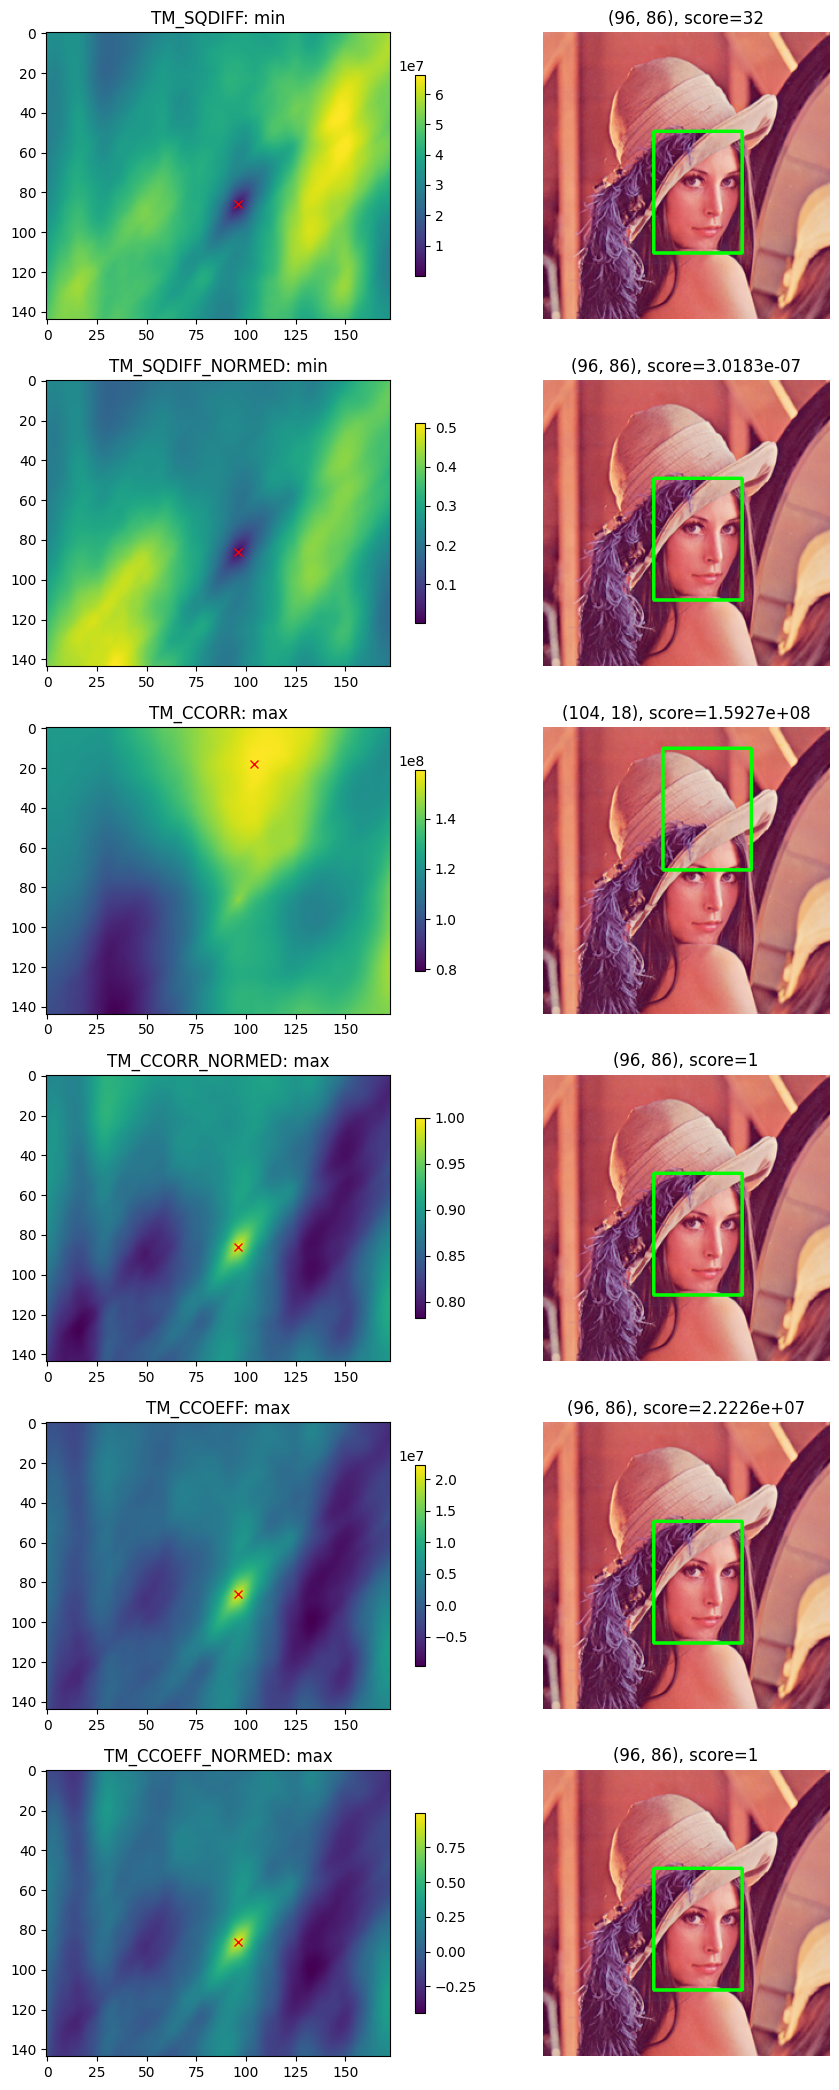

In [4]:
# 셀 4: 응답 맵과 검출 위치 표시
# 응답 맵의 좌표는 템플릿 왼쪽 위 위치이며, 같은 좌표에 템플릿 크기의 상자를 그린다.

fig, axes = plt.subplots(6, 2, figsize=(10, 21))
for i, row in enumerate(rows):
    name, x, y = row['method'], row['x'], row['y']
    im = axes[i, 0].imshow(responses[name], cmap='viridis')
    axes[i, 0].plot(x, y, 'rx')
    axes[i, 0].set_title(f"{name}: {row['best']}")
    fig.colorbar(im, ax=axes[i, 0], shrink=.7)
    marked = bgr.copy()
    # 오른쪽 아래 좌표도 포함해 그린다. 폭·높이에서 1을 빼면 지정한 픽셀 범위와 맞는다.
    cv2.rectangle(marked, (x, y), (x+w-1, y+h-1), (0, 255, 0), 2)
    axes[i, 1].imshow(cv2.cvtColor(marked, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"({x}, {y}), score={row['score']:.5g}")
    axes[i, 1].axis('off')
save_show(fig, 'six_methods.png')

### 셀 5. 대표 결과 저장

파일 이름은 `template_matching_result.png`로 명확히 정한다. 이전에 사용한 `result_detection.jpg`라는 이름만으로 템플릿 매칭 결과인지 판단할 수 없다. `threshold → morphology → findContours → boundingRect` 코드는 외곽선 기반 영역 표시이며, `matchTemplate()` 기반 탐색과 다르다.

최적 위치는 항상 하나 나온다. **대상이 실제로 있다는 보장은 아니다.** 실제 검출에서는 검증 데이터로 임계값을 정하고, 반복 무늬·비슷한 후보·미검출 사례도 확인해야 한다. 여러 대상을 찾으려면 임계값 통과 후보와 중복 제거(NMS) 같은 별도 처리가 필요하다.

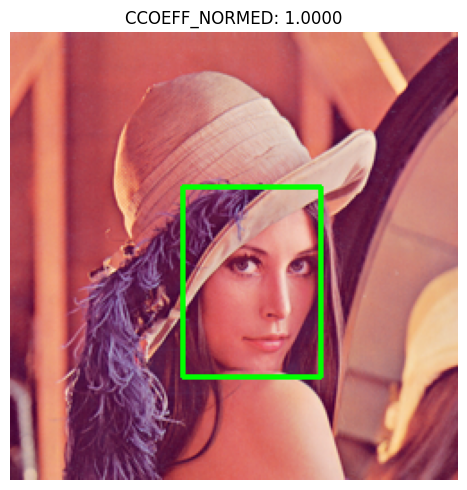

선택 위치: (96, 86) 영역 크기: (78, 107)


In [5]:
# 셀 5: 정규화 상관 계수 결과 저장
# TM_CCOEFF_NORMED의 최적 위치를 선택하여 표시용 그림과 검출 영상을 저장한다.

chosen = next(row for row in rows if row['method'] == 'TM_CCOEFF_NORMED')
x, y = chosen['x'], chosen['y']
result = bgr.copy()
# 오른쪽 아래 좌표도 포함해 그린다. 폭·높이에서 1을 빼면 지정한 픽셀 범위와 맞는다.
cv2.rectangle(result, (x,y), (x+w-1,y+h-1), (0,255,0), 2)
ok, encoded = cv2.imencode('.png', result)
assert ok
encoded.tofile(ASSETS / 'template_matching_result.png')
fig, ax = plt.subplots(figsize=(5,5))
ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB)); ax.axis('off')
ax.set_title(f"CCOEFF_NORMED: {chosen['score']:.4f}")
save_show(fig, 'best_match.png')
print('선택 위치:', (x,y), '영역 크기:', (w,h))

## 5.4 회전 및 크기 변화에 대한 한계

- 기본 템플릿 매칭은 위치를 옮기지만, 각도와 크기를 자동으로 탐색하지 않는다.
- 같은 물체라도 회전·축소·확대되면 픽셀 배치가 달라진다.
- 좋은 점수가 나올 때도 있지만 회전·크기 불변성을 가진 것은 아니다.

### 셀 6. 정답 위치를 아는 통제 실험

레나에서 고정 영역을 직접 잘라 기준 조각으로 삼는다. 이 조각과 회전·확대한 조각을 **각각 별도의 배경**에 붙이고 원래 조각으로 찾는다. 제공 템플릿의 추정 위치를 정답으로 쓰지 않는다.

주황 사각형은 붙인 조각의 전체 범위, 초록 사각형은 검출한 범위다. 회전은 캔버스를 넓혀 잘림을 줄였지만 배경·보간도 바뀐다. 따라서 점수 차이를 순수한 각도 효과만으로 해석하지 않는다.

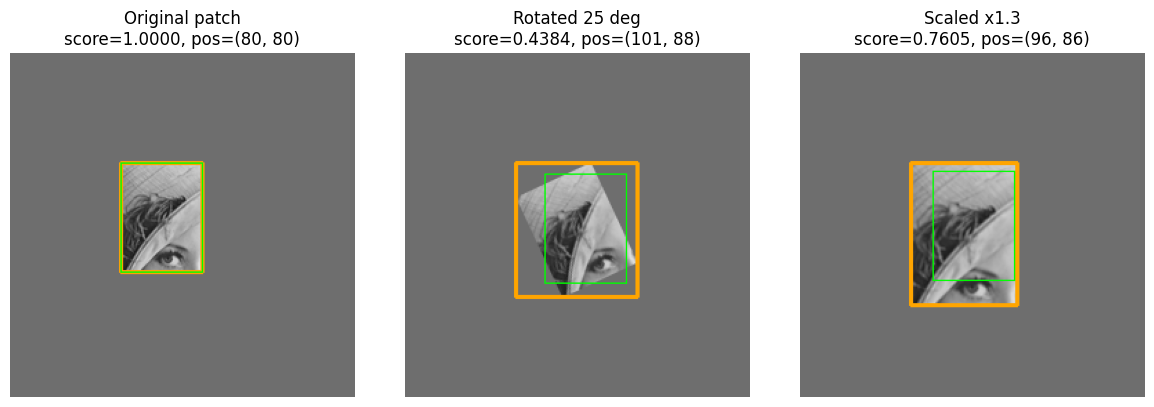

[
  {
    "case": "Original patch",
    "score": 1.0,
    "x": 80,
    "y": 80
  },
  {
    "case": "Rotated 25 deg",
    "score": 0.4383848309516907,
    "x": 101,
    "y": 88
  },
  {
    "case": "Scaled x1.3",
    "score": 0.7604975700378418,
    "x": 96,
    "y": 86
  }
]


In [6]:
# 셀 6: 회전·크기 변화에 대한 통제 실험
# 같은 원본 패치를 회전·확대하여 넣고, 변형하지 않은 템플릿으로 찾았을 때의 점수를 비교한다.

base = image[60:140, 95:155].copy()
bh, bw = base.shape
angle = 25
# 패치 중심을 기준으로 회전하며, 다음 단계에서 캔버스 크기와 이동량을 보정한다.
M = cv2.getRotationMatrix2D(((bw-1)/2, (bh-1)/2), angle, 1.0)
c, s = abs(M[0,0]), abs(M[0,1])
nw, nh = int(np.ceil(bw*c+bh*s)), int(np.ceil(bh*c+bw*s))
M[0,2] += (nw-bw)/2; M[1,2] += (nh-bh)/2
# 확장한 캔버스에 회전 패치를 배치하고 빈 곳은 배경값 110으로 채운다.
rot = cv2.warpAffine(base, M, (nw,nh), borderValue=110)
# 가로·세로를 각각 1.3배로 보간하여 크기 변화 실험용 패치를 만든다.
scaled = cv2.resize(base, None, fx=1.3, fy=1.3, interpolation=cv2.INTER_LINEAR)
variants = [('Original patch', base), ('Rotated 25 deg', rot), ('Scaled x1.3', scaled)]
experiment = []
fig, axes = plt.subplots(1,3,figsize=(12,4))
for ax, (label, patch) in zip(axes, variants):
    canvas = np.full((250,250), 110, np.uint8)
    px, py = 80, 80
    ph, pw = patch.shape
    canvas[py:py+ph, px:px+pw] = patch
    # 템플릿을 움직이며 위치별 점수를 계산한다. 출력의 각 축 크기는 입력 크기에서 템플릿 크기를 뺀 뒤 1을 더한 값이다.
    response = cv2.matchTemplate(canvas, base, cv2.TM_CCOEFF_NORMED)
    _, score, _, loc = cv2.minMaxLoc(response)
    foundx, foundy = loc
    marked = cv2.cvtColor(canvas, cv2.COLOR_GRAY2RGB)
    # 오른쪽 아래 좌표도 포함해 그린다. 폭·높이에서 1을 빼면 지정한 픽셀 범위와 맞는다.
    cv2.rectangle(marked,(px,py),(px+pw-1,py+ph-1),(255,165,0),2)
    # 오른쪽 아래 좌표도 포함해 그린다. 폭·높이에서 1을 빼면 지정한 픽셀 범위와 맞는다.
    cv2.rectangle(marked,loc,(foundx+bw-1,foundy+bh-1),(0,255,0),1)
    ax.imshow(marked);ax.axis('off');ax.set_title(f'{label}\nscore={score:.4f}, pos={loc}')
    experiment.append({'case':label,'score':score,'x':foundx,'y':foundy})
assert experiment[0]['score'] > .999
assert (experiment[0]['x'],experiment[0]['y']) == (80,80)
save_show(fig, 'rotation_scale.png')
print(json.dumps(experiment, indent=2))
# 수치 결과를 UTF-8 JSON으로 저장하여 그림과 별도로 확인할 수 있게 한다.
(ROOT/'experiment_results.json').write_text(json.dumps(experiment, indent=2), encoding='utf-8')

### 보완 방법과 다음 학습

| 상황 | 가능한 방법 | 고려할 점 |
| :---: | :---: | :---: |
| 크기가 조금 달라짐 | 여러 크기의 템플릿 탐색 | 계산량·후보 수 증가 |
| 각도가 조금 달라짐 | 여러 각도의 템플릿 탐색 | 보간·여백·탐색 간격 영향 |
| 회전·스케일 변화가 큼 | SIFT·ORB 등의 특징점 매칭 | 텍스처와 대응점 필요 |
| 가림·모양 변화가 큼 | 목적에 맞는 검출 모델 등 | 별도 데이터·검증 필요 |

각도·크기를 많이 탐색하면 우연히 높은 점수가 나올 가능성도 커지므로 임계값을 다시 검증한다. 이번 노트북은 기본 매칭과 한계 관찰까지 다룬다.

## 체크리스트

- [ ] 응답 맵 크기를 계산할 수 있다.
- [ ] SQDIFF 계열만 최솟값을 선택한다는 것을 안다.
- [ ] CCOEFF와 CCOEFF_NORMED의 범위를 혼동하지 않는다.
- [ ] 점수를 검출 확률로 해석하지 않는다.
- [ ] 항상 나오는 최적 위치와 실제 검출 성공을 구분한다.

## 참고 문서

- [OpenCV — Template Matching](https://docs.opencv.org/4.x/d4/dc6/tutorial_py_template_matching.html)
- [OpenCV — TemplateMatchModes 수식과 API](https://docs.opencv.org/4.x/df/dfb/group__imgproc__object.html)

원본·템플릿은 사용자가 제공한 파일이며, 통제 실험은 레나의 별도 고정 영역으로 구성했다.


## 실행 확인 방식

제공 환경에서 Jupyter 커널의 소켓 생성이 제한되어, 코드 셀을 하나의 Python 실행 공간에서 순서대로 실행하고 출력·그림을 노트북에 저장했다. 모든 코드 셀과 검증문은 통과했다. 실제 Jupyter 커널에서의 Run All은 이 환경에서 확인하지 못했다.